In [ ]:
import marimo as mo

# Análisis exploratorio: colonias de Hermosillo

`colonias_hermosillo.csv` es el catálogo de asentamientos del municipio según el DCAH 2025
del INEGI: una fila por colonia, fraccionamiento o residencial, con su clave, nombre,
tipo, código postal, área y centroide. Es el catálogo contra el que se resuelven las
colonias que nombran los avisos, así que su calidad decide la del desglose territorial.

El catálogo por sí solo tiene pocas variables numéricas (área y centroide). Para que las
relaciones, la correlación y la reducción de dimensión digan algo sobre el problema, a
cada colonia se le agregan variables que salen de los otros dos datasets tidy del
proyecto: cuántas publicaciones la mencionan, cómo se resolvieron esas menciones y cuánto
enojo generaron esas publicaciones.

## Objetivos

1. Auto EDA con ydata-profiling, publicado en `docs/eda/`.
2. Datos faltantes, incluidos los que el catálogo codifica como valores válidos.
3. Anomalías con regla de Tukey y PyOD (IForest, ECOD y LOF).
4. Relaciones entre variables por visualización.
5. Correlación entre variables numéricas y categóricas.
6. Reducción a 2D con PCA, t-SNE y UMAP.
7. Preguntas para los usuarios.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

from project_name.eda import (
    CATEGORICAL,
    NEUTRAL,
    agreement_table,
    category_colors,
    correlation_ratio,
    cramers_v_matrix,
    embed_2d,
    embedding_quality,
    iqr_outliers,
    missing_table,
    plot_embeddings,
    plot_heatmap,
    processed_path,
    pyod_outliers,
    run_ydata_profile,
    ydata_summary,
)

DATASET = "colonias_hermosillo"
pd.set_option("display.max_rows", 60)

## 1. Auto EDA con ydata-profiling

Reporte completo:
[`docs/eda/colonias_hermosillo.html`](../../docs/eda/colonias_hermosillo.html), generado
por `scripts/ydata_profile.py` en su propio entorno (ydata-profiling 4.18 exige
pandas<3). Las claves (`colonia_id`, `locality_code`, `postal_code`) se leen como texto
para que el reporte no las trate como cantidades.

In [ ]:
report_html = run_ydata_profile(DATASET)
ydata_overview, ydata_alerts = ydata_summary(DATASET)
ydata_overview.to_frame("valor")

,valor
filas,783
columnas,10
celdas faltantes,0
% celdas faltantes,0.0
columnas con faltantes,0
filas duplicadas,0
memoria (MB),0.35
tipo Numeric,5
tipo Text,2
tipo Categorical,3


In [ ]:
ydata_alerts

,columna,alerta,detalle
0,centroid_lat,alta correlación,is highly overall correlated with [locality_code] and 2 other fields
1,centroid_lon,alta correlación,is highly overall correlated with [locality_code] and 1 other fields
2,colonia_id,alta correlación,is highly overall correlated with [locality_code] and 2 other fields
3,locality_code,alta correlación,is highly overall correlated with [centroid_lat] and 4 other fields
4,postal_code,alta correlación,is highly overall correlated with [centroid_lat] and 2 other fields
5,settlement_type,alta correlación,is highly overall correlated with [colonia_id]
6,updated_at,alta correlación,is highly overall correlated with [centroid_lat] and 4 other fields
7,postal_code,ceros,has 20 (2.6%) zeros
8,locality_code,desbalanceada,is highly imbalanced (0.8709067753530239)
9,settlement_type,desbalanceada,is highly imbalanced (0.5397359579548253)


El reporte no encuentra nulos ni duplicados. Sus alertas apuntan a otra cosa: la
localidad, la fecha de actualización, el código postal y el centroide se mueven juntos, y
`postal_code` tiene 20 "ceros". Las dos cosas tienen la misma causa, que se revisa en la
sección 2: el catálogo mezcla la ciudad con dos localidades rurales.

## 2. Datos faltantes

In [ ]:
colonias = pd.read_csv(
    processed_path(DATASET),
    dtype={"colonia_id": str, "locality_code": str, "postal_code": str},
)
colonias.shape

In [ ]:
missing_table(colonias)

,nulos,vacios,% nulos,% vacios


No hay nulos ni cadenas vacías. Pero un catálogo puede codificar el faltante como un valor
válido. Se buscan tres casos: el código postal `00000` (el diccionario dice "00000 si no
lo reportó"), el tipo de asentamiento `NINGUNO` y la fecha de actualización distinta a la
del resto.

In [ ]:
LOCALITIES = {"0001": "Hermosillo (ciudad)", "0137": "Bahía de Kino", "0343": "Miguel Alemán"}
hidden_missing = {
    "postal_code = 00000": colonias["postal_code"] == "00000",
    "settlement_type = NINGUNO": colonias["settlement_type"] == "NINGUNO",
    "updated_at = 11/2022": colonias["updated_at"] == "11/2022",
}
pd.DataFrame(
    {
        rule: colonias.loc[mask, "locality_code"].map(LOCALITIES).value_counts()
        for rule, mask in hidden_missing.items()
    }
).fillna(0).astype(int).T.assign(total=lambda frame: frame.sum(axis=1))

locality_code,Bahía de Kino,Hermosillo (ciudad),Miguel Alemán,total
postal_code = 00000,12,0,8,20
settlement_type = NINGUNO,0,4,0,4
updated_at = 11/2022,12,0,9,21


In [ ]:
colonias.loc[
    colonias["settlement_type"] == "NINGUNO",
    ["colonia_id", "settlement_name", "postal_code", "area_km2"],
]

,colonia_id,settlement_name,postal_code,area_km2
256,2603000010291,Plaza de las Franquicias,83200,0.0464
368,2603000010464,Central de Abastos,83293,0.2891
615,2603000010809,Comercial Cedros,83295,0.1122
663,2603000010857,Altares,83283,0.0209


- Los 20 códigos postales `00000` son todos de Bahía de Kino (12) y Miguel Alemán (8):
  el municipio no reportó código postal para esas localidades. Faltante MNAR
  (depende de la localidad, que sí está en la tabla). Se deja como nulo al analizar; no
  se imputa porque el código postal no se usa para emparejar avisos.
- Los 4 `NINGUNO` son lugares comerciales (Plaza de las Franquicias, Central de Abastos,
  Comercial Cedros) y Altares; es una categoría real del INEGI, no un faltante.
- Los 21 asentamientos con `updated_at = 11/2022` son exactamente los de Bahía de Kino y
  Miguel Alemán: el municipio no los actualizó en 2025.

Hay otra forma de faltante que importa para el proyecto: colonias del catálogo que ningún
aviso menciona. Para medirla se cruzan las colonias con `ubicaciones_aviso`.

In [ ]:
locations = pd.read_csv(
    processed_path("ubicaciones_aviso"), dtype={"post_id": str, "colonia_id": str}
)
posts = pd.read_csv(
    processed_path("publicaciones_aguah"),
    dtype={"post_id": str},
    usecols=["post_id", "event_type", "angry_share", "reactions_total"],
)
# Una colonia puede salir dos veces en el mismo aviso (por nombre y por un cruce); para
# contar publicaciones por colonia basta una vez.
mentions = (
    locations.dropna(subset=["colonia_id"])
    .merge(posts, on="post_id", how="left")
    .assign(
        is_cross=lambda frame: frame["location_type"] == "cruce",
        from_ocr=lambda frame: frame["source_field"] != "texto",
        explicit=lambda frame: frame["match_method"] != "colonia_en_catalogo",
    )
)
mention_features = mentions.groupby("colonia_id").agg(
    n_mentions=("post_id", "size"),
    n_posts=("post_id", "nunique"),
    share_cross=("is_cross", "mean"),
    share_ocr=("from_ocr", "mean"),
    share_explicit=("explicit", "mean"),
    angry_share_mean=("angry_share", "mean"),
    share_emergency=("event_type", lambda s: (s == "emergencia").mean()),
)
colonia_profile = colonias.merge(mention_features, on="colonia_id", how="left").assign(
    mentioned=lambda frame: frame["n_posts"].notna(),
    n_posts=lambda frame: frame["n_posts"].fillna(0),
    n_mentions=lambda frame: frame["n_mentions"].fillna(0),
    log_area=lambda frame: frame["area_km2"].apply("log"),
)
colonia_profile.shape

In [ ]:
pd.crosstab(
    colonia_profile["locality_code"].map(LOCALITIES),
    colonia_profile["mentioned"].map({True: "mencionada", False: "nunca mencionada"}),
    margins=True,
)

mentioned,mencionada,nunca mencionada,All
locality_code,,,
Bahía de Kino,2,10,12
Hermosillo (ciudad),556,206,762
Miguel Alemán,4,5,9
All,562,221,783


In [ ]:
pd.crosstab(
    colonia_profile["settlement_type"],
    colonia_profile["mentioned"],
    normalize="index",
).mul(100).round(1).rename(columns={True: "% mencionada", False: "% nunca"}).join(
    colonia_profile["settlement_type"].value_counts().rename("colonias")
).sort_values("colonias", ascending=False)

,% nunca,% mencionada,colonias
settlement_type,,,
FRACCIONAMIENTO,35.4,64.6,398
COLONIA,15.7,84.3,300
RESIDENCIAL,42.4,57.6,33
PRIVADA,21.1,78.9,19
PARQUE INDUSTRIAL,45.5,54.5,11
AMPLIACIÓN,71.4,28.6,7
BARRIO,25.0,75.0,4
CONDOMINIO,50.0,50.0,4
NINGUNO,25.0,75.0,4


562 de las 783 colonias (72%) aparecen en al menos un aviso; 221 nunca. De estas, 206 son
de la ciudad. Las colonias tradicionales casi siempre aparecen y los fraccionamientos,
residenciales y privadas mucho menos. En el tablero, "sin avisos" no debe pintarse igual
que "cero problemas": puede ser una colonia que el organismo nombra de otra forma o que se
abastece de otra red.

Las variables de menciones (`share_cross`, `share_ocr`, `share_explicit`,
`angry_share_mean`, `share_emergency`) no están definidas para las colonias nunca
mencionadas. Se dejan nulas para describir y se llenan con 0, junto con la bandera
`mentioned`, solo en las técnicas que no aceptan nulos (PyOD, PCA, t-SNE y UMAP).

### Nombres repetidos

Los avisos nombran colonias, no claves. Si dos asentamientos se llaman igual, el aviso es
ambiguo.

In [ ]:
duplicated_names = colonias[
    colonias["settlement_name_normalized"].duplicated(keep=False)
].sort_values(["settlement_name_normalized", "settlement_type"])
print(
    f"{duplicated_names['settlement_name_normalized'].nunique()} nombres repetidos en "
    f"{len(duplicated_names)} asentamientos"
)
duplicated_names[
    ["settlement_name", "settlement_type", "locality_code", "postal_code", "area_km2"]
]

18 nombres repetidos en 38 asentamientos


,settlement_name,settlement_type,locality_code,postal_code,area_km2
608,4 de Marzo,AMPLIACIÓN,0001,83105,0.0528
299,4 de Marzo,COLONIA,0001,83105,0.2469
304,Altares,FRACCIONAMIENTO,0001,83296,2.0637
663,Altares,NINGUNO,0001,83283,0.0209
36,Casa Blanca,COLONIA,0001,83079,0.3779
593,Casa Blanca,PRIVADA,0001,83079,0.0030
355,El Mirador,AMPLIACIÓN,0001,83179,0.0466
392,El Mirador,COLONIA,0001,83179,0.0929
80,Heberto Castillo,COLONIA,0001,83106,0.2933
742,Heberto Castillo,COLONIA,0001,83105,0.1388


18 nombres corresponden a 38 asentamientos. Casi siempre es una colonia y su ampliación,
privada o etapa con el mismo nombre (4 de Marzo, El Mirador, Ladrilleras), con el mismo
código postal. Un aviso que dice "4 de Marzo" no permite saber cuál de las dos es.

## 3. Anomalías

1. Univariada: regla de Tukey sobre el área, en escala original y en logaritmo (el área va
   de 0.0009 a 4.49 km², con sesgo fuerte a la derecha).
2. Multivariada con PyOD sobre logaritmo del área, latitud, longitud y `log1p(n_posts)`,
   estandarizadas, con `contamination=0.03` (24 colonias por detector).

In [ ]:
tukey_area = pd.DataFrame(
    {
        "area_km2": iqr_outliers(colonia_profile["area_km2"]),
        "log_area": iqr_outliers(colonia_profile["log_area"]),
    }
)
tukey_area.sum().rename("anómalas (Tukey)").to_frame()

,anómalas (Tukey)
area_km2,74
log_area,14


In [ ]:
colonia_profile.loc[
    tukey_area["log_area"], ["settlement_name", "settlement_type", "area_km2", "n_posts"]
].sort_values("area_km2")

,settlement_name,settlement_type,area_km2,n_posts
736,Torre Altitud M,CONDOMINIO,0.0009,0.0
158,Prados de Bugambilias II,COLONIA,0.0018,0.0
600,San Bernardino Etapa 4,FRACCIONAMIENTO,0.0019,0.0
587,Lomas de Barrocan,COLONIA,0.0028,0.0
593,Casa Blanca,PRIVADA,0.0030,0.0
568,Hacienda Real,CONDOMINIO,0.0042,4.0
21,Balderrama,COLONIA,1.7146,134.0
132,Olivares,COLONIA,1.8018,214.0
304,Altares,FRACCIONAMIENTO,2.0637,133.0
42,Centro,COLONIA,2.1299,390.0


In [ ]:
_features = colonia_profile[["log_area", "centroid_lat", "centroid_lon"]].assign(
    log_posts=np.log1p(colonia_profile["n_posts"])
)
_scaled = pd.DataFrame(StandardScaler().fit_transform(_features), columns=_features.columns)
colonia_outliers = pyod_outliers(_scaled, contamination=0.03)
agreement_table(
    colonia_outliers.filter(like="_outlier").assign(tukey_log_area=tukey_area["log_area"])
)

,iforest_outlier,ecod_outlier,lof_outlier,tukey_log_area
iforest_outlier,1.00,0.55,0.07,0.09
ecod_outlier,0.55,1.00,0.17,0.12
lof_outlier,0.07,0.17,1.00,0.31
tukey_log_area,0.09,0.12,0.31,1.00


In [ ]:
colonia_profile.loc[
    colonia_outliers["votes"] >= 2,
    ["settlement_name", "settlement_type", "locality_code", "area_km2", "n_posts"],
].assign(
    localidad=lambda frame: frame["locality_code"].map(LOCALITIES),
    votos=colonia_outliers["votes"],
).sort_values(["localidad", "n_posts"], ascending=[True, False])

,settlement_name,settlement_type,locality_code,area_km2,n_posts,localidad,votos
770,LAS FUENTES,COLONIA,0137,0.2936,14.0,Bahía de Kino,2
773,MEDITERRÁNEO,COLONIA,0137,0.3700,7.0,Bahía de Kino,2
762,ALCATRÁZ/KINO VIEJO,COLONIA,0137,0.1649,0.0,Bahía de Kino,2
764,CARNAVALITO/KINO VIEJO,COLONIA,0137,0.2026,0.0,Bahía de Kino,2
765,CENTRO/KINO VIEJO,COLONIA,0137,0.1535,0.0,Bahía de Kino,2
766,BARRIO DE LA CRUZ/KINO VIEJO,BARRIO,0137,0.2043,0.0,Bahía de Kino,2
767,LOMA LINDA/KINO VIEJO,COLONIA,0137,0.1811,0.0,Bahía de Kino,2
768,PRIMAVERA/KINO VIEJO,COLONIA,0137,0.2965,0.0,Bahía de Kino,2
769,PROGRESO/KINO VIEJO,COLONIA,0137,0.0971,0.0,Bahía de Kino,2
771,LOMAS DE KINO,COLONIA,0137,1.2558,0.0,Bahía de Kino,2


IForest y ECOD coinciden en 55% de sus marcas; LOF casi no coincide con ellos (7% a 17%)
y se parece más a Tukey sobre el área (31%), porque marca puntos aislados en su vecindad.
Las 21 colonias marcadas por al menos dos detectores forman dos grupos:

- Geográficas: 11 asentamientos de Bahía de Kino y 3 de Miguel Alemán, a 50 y 100 km de
  la ciudad. No son errores, pero sí otra población: el tablero de la ciudad debería
  filtrarlos o mostrarlos aparte.
- De tamaño y menciones: Centro, Altares, Palo Verde, Nuevo Hermosillo y tres parques
  industriales, las colonias más grandes o más mencionadas de la ciudad.

Tukey sobre el logaritmo del área encuentra además los asentamientos diminutos (un
condominio de 900 m², privadas y etapas de 2,000 a 4,000 m²), que son reales. Sobre el
área sin logaritmo marca 74, casi todo colonias grandes normales: con sesgo tan fuerte la
regla necesita la transformación.

Lo que sí parece un error es que haya colonias rurales mencionadas en avisos del organismo
de agua de la ciudad. La tabla siguiente muestra qué texto produjo esas menciones:

In [ ]:
_rural = colonias.loc[
    colonias["locality_code"] != "0001", ["colonia_id", "settlement_name", "locality_code"]
]
locations.merge(_rural, on="colonia_id").assign(
    localidad=lambda frame: frame["locality_code"].map(LOCALITIES)
).groupby(["localidad", "settlement_name", "raw_text", "match_method"]).size().rename(
    "menciones"
).sort_values(ascending=False).to_frame()

menciones localidad settlement_name raw_text match_method Miguel Alemán LOS VIÑEDOS LOS VINEDOS colonia_en_catalogo 16 Bahía de Kino LAS FUENTES LAS FUENTES colonia_en_catalogo 11 Miguel Alemán SALVADOR ALVARADO SALVADOR ALVARADO colonia_en_catalogo 10 Bahía de Kino MEDITERRÁNEO MEDITERRANEO colonia_en_catalogo 7 Miguel Alemán SECTOR A SECTOR A colonia_en_catalogo 6 LOS VIÑEDOS LOS VINEDOS colonia_con_marcador 4 Bahía de Kino LAS FUENTES LAS FUENTES colonia_con_marcador 3 Miguel Alemán MANUEL J. CLOUTHIER MANUEL J CLOUTHIER colonia_en_catalogo 1

Hay 58 menciones resueltas a colonias rurales; 51 por `colonia_en_catalogo` (el nombre
suelto) y 7 con marcador ("colonia Los Viñedos", "colonia Las Fuentes"). Son nombres que
en la ciudad corresponden a otra cosa (un fraccionamiento que el DCAH registra con otro
nombre, una calle o bulevar como Salvador Alvarado, o una etiqueta genérica como "Sector
A") y que el emparejamiento resolvió a la única coincidencia del catálogo, en Kino o
Miguel Alemán. Son falsos positivos probables del proceso de `ubicaciones_aviso`: conviene
restringir el catálogo de emparejamiento a la localidad 0001 o confirmarlo con los
usuarios (pregunta 3).

## 4. Relaciones entre variables por visualización

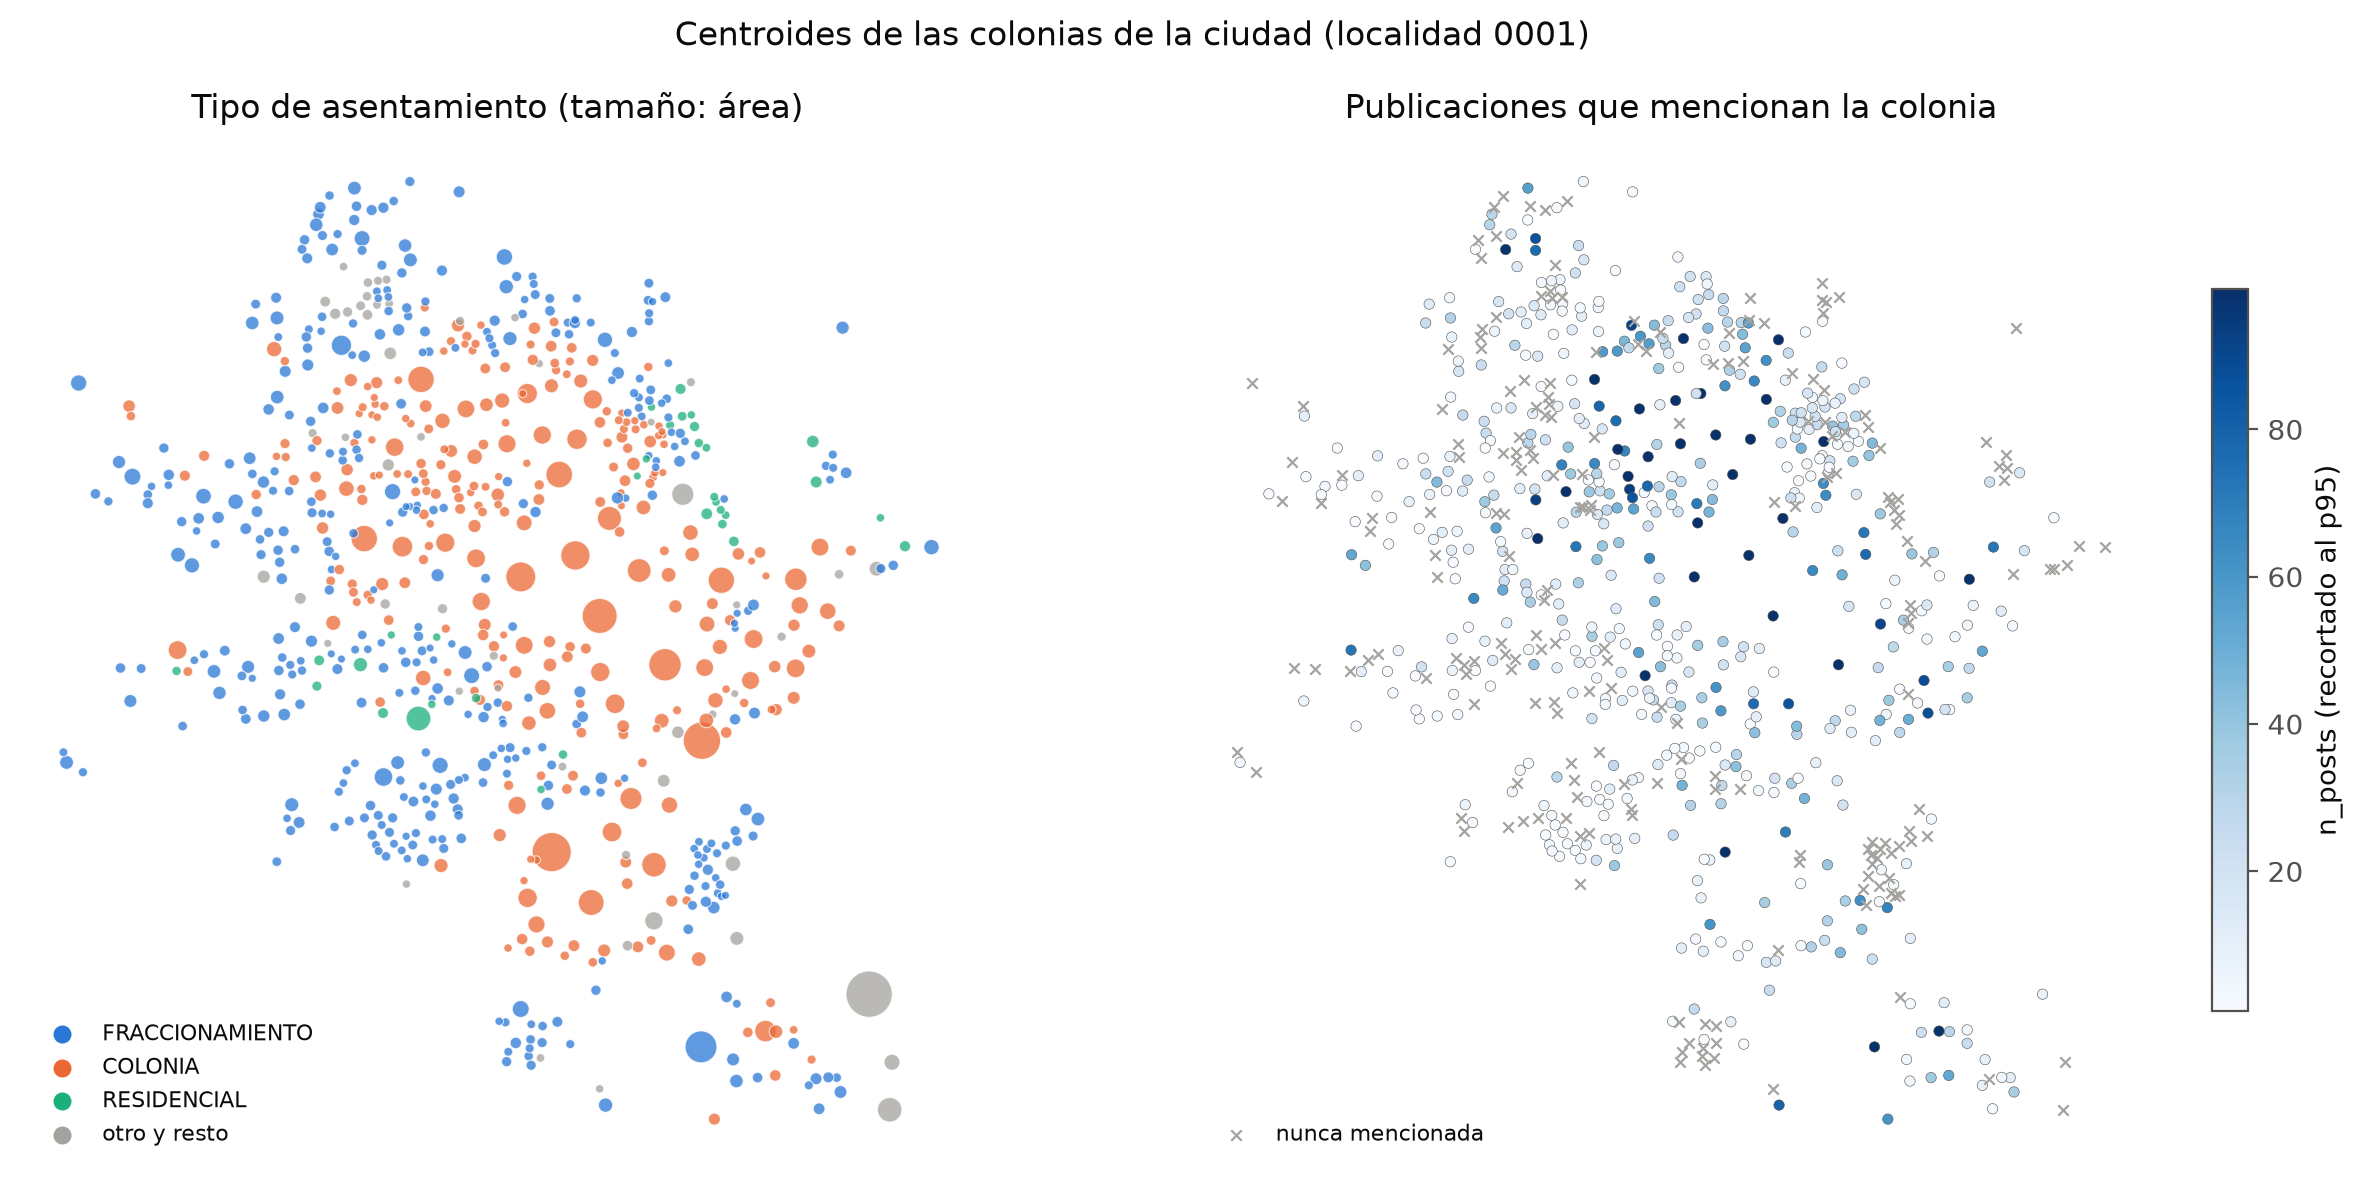

In [ ]:
_city = colonia_profile[colonia_profile["locality_code"] == "0001"]
_colors, _legend = category_colors(_city["settlement_type"], top=3, other="otro")
_fig, _axes = plt.subplots(1, 2, figsize=(13, 6))
_axes[0].scatter(
    _city["centroid_lon"],
    _city["centroid_lat"],
    s=8 + 60 * _city["area_km2"],
    c=_colors,
    alpha=0.75,
    edgecolors="white",
    linewidths=0.4,
)
_axes[0].set_title("Tipo de asentamiento (tamaño: área)")
for _label, _color in _legend.items():
    _axes[0].scatter([], [], color=_color, label=_label, s=30)
_axes[0].legend(frameon=False, loc="lower left", fontsize=8)
_never = _city["n_posts"] == 0
_scatter = _axes[1].scatter(
    _city.loc[~_never, "centroid_lon"],
    _city.loc[~_never, "centroid_lat"],
    s=14,
    c=_city.loc[~_never, "n_posts"].pipe(lambda s: s.clip(upper=s.quantile(0.95))),
    cmap="Blues",
    edgecolors="#52514e",
    linewidths=0.2,
)
_axes[1].scatter(
    _city.loc[_never, "centroid_lon"],
    _city.loc[_never, "centroid_lat"],
    s=14,
    marker="x",
    color=NEUTRAL,
    linewidths=0.8,
    label="nunca mencionada",
)
_axes[1].legend(frameon=False, loc="lower left", fontsize=8)
_axes[1].set_title("Publicaciones que mencionan la colonia")
_fig.colorbar(_scatter, ax=_axes[1], shrink=0.7, label="n_posts (recortado al p95)")
for _ax in _axes:
    _ax.set_aspect("equal")
    _ax.set_xticks([])
    _ax.set_yticks([])
    _ax.spines[:].set_visible(False)
_fig.suptitle("Centroides de las colonias de la ciudad (localidad 0001)")
_fig.tight_layout()
_fig

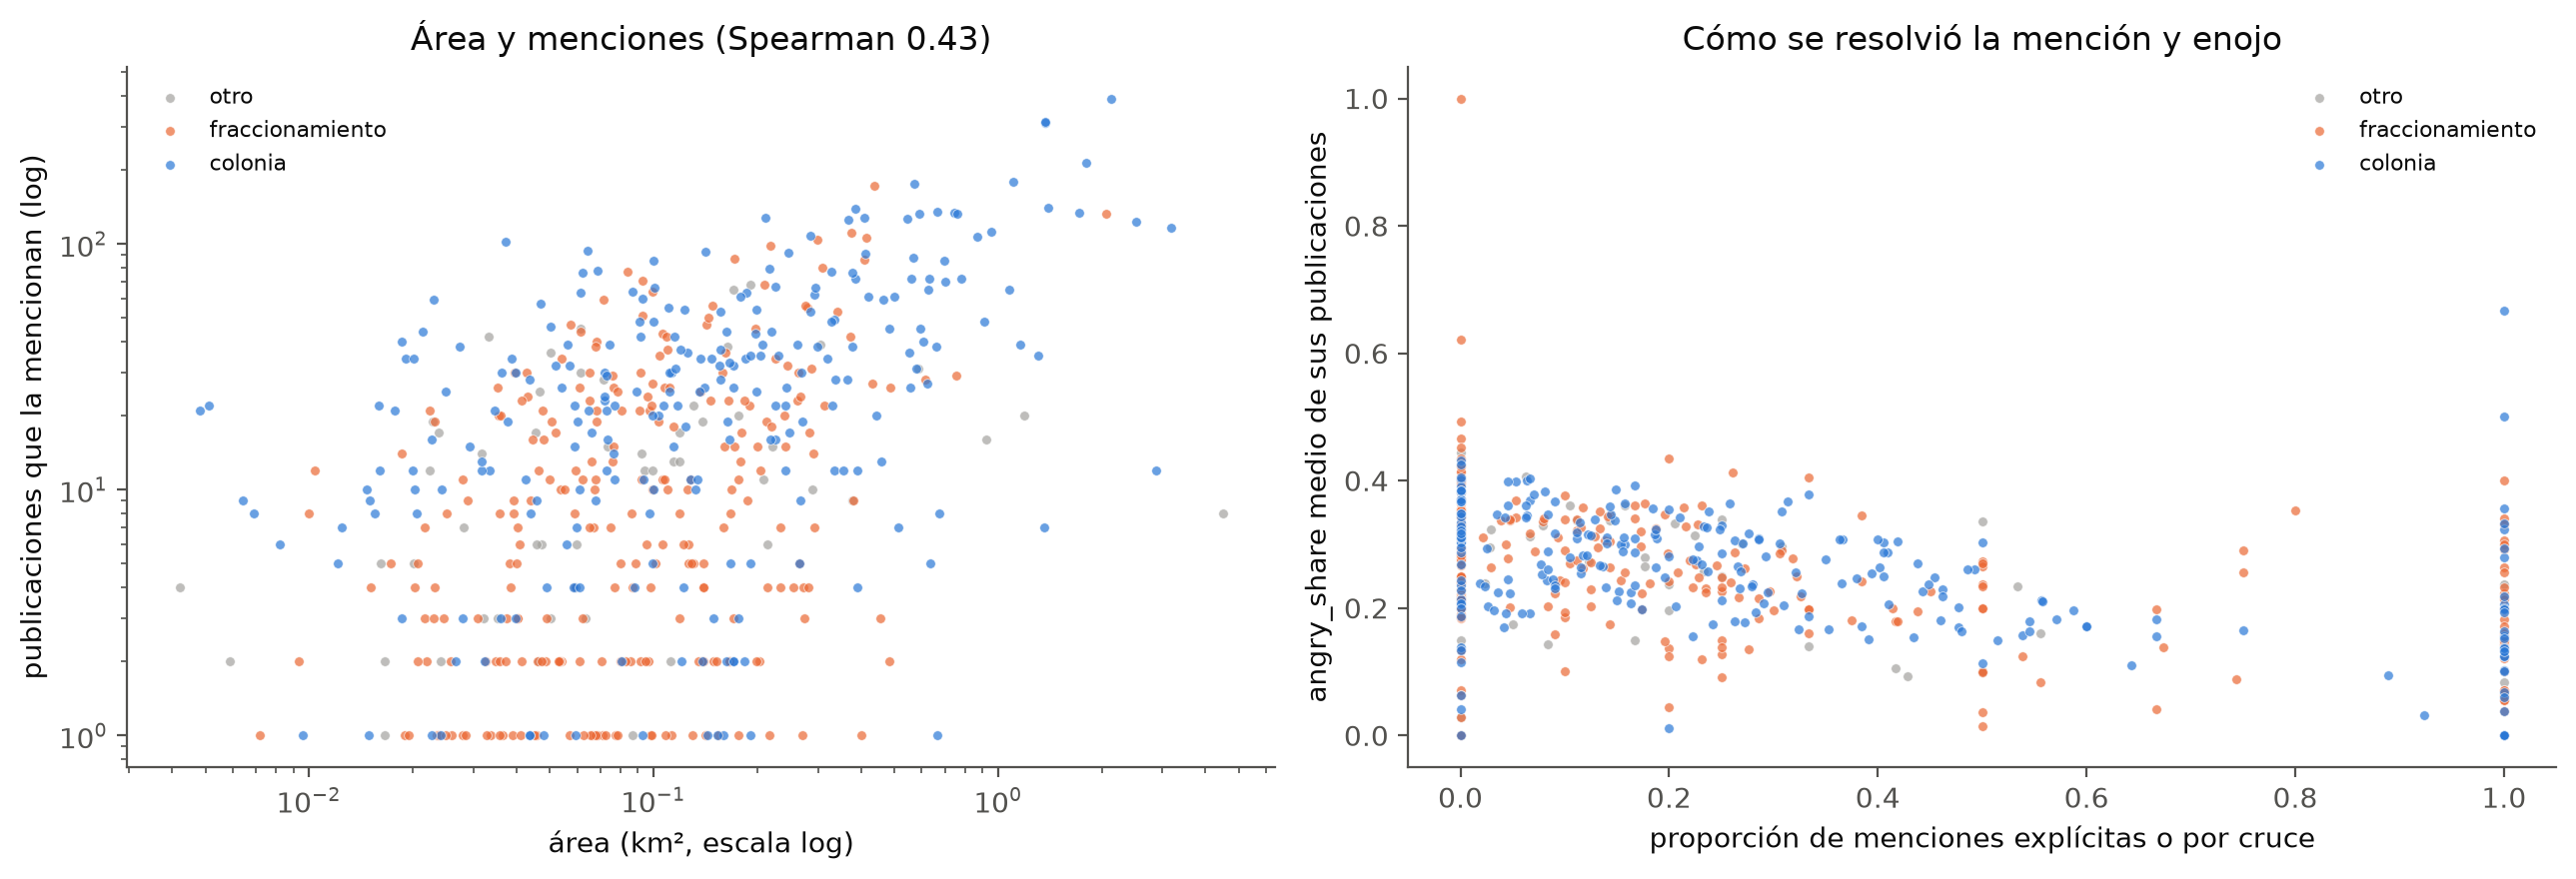

In [ ]:
_city = colonia_profile[
    (colonia_profile["locality_code"] == "0001") & colonia_profile["mentioned"]
]
_palette = {"COLONIA": CATEGORICAL[0], "FRACCIONAMIENTO": CATEGORICAL[1]}
_fig, _axes = plt.subplots(1, 2, figsize=(13, 4.5))
for _type in ["otro", "FRACCIONAMIENTO", "COLONIA"]:
    _subset = (
        _city[~_city["settlement_type"].isin(_palette)]
        if _type == "otro"
        else _city[_city["settlement_type"] == _type]
    )
    _color = _palette.get(_type, NEUTRAL)
    _axes[0].scatter(
        _subset["area_km2"],
        _subset["n_posts"],
        s=12,
        color=_color,
        alpha=0.7,
        edgecolors="white",
        linewidths=0.3,
        label=_type.lower(),
    )
    _axes[1].scatter(
        _subset["share_explicit"],
        _subset["angry_share_mean"],
        s=12,
        color=_color,
        alpha=0.7,
        edgecolors="white",
        linewidths=0.3,
        label=_type.lower(),
    )
_axes[0].set_xscale("log")
_axes[0].set_yscale("log")
_axes[0].set_xlabel("área (km², escala log)")
_axes[0].set_ylabel("publicaciones que la mencionan (log)")
_axes[0].set_title(
    f"Área y menciones (Spearman {_city['area_km2'].corr(_city['n_posts'], method='spearman'):.2f})"
)
_axes[1].set_xlabel("proporción de menciones explícitas o por cruce")
_axes[1].set_ylabel("angry_share medio de sus publicaciones")
_axes[1].set_title("Cómo se resolvió la mención y enojo")
for _ax in _axes:
    _ax.legend(frameon=False, fontsize=8)
    _ax.spines[["top", "right"]].set_visible(False)
_fig.tight_layout()
_fig

In [ ]:
colonia_profile.groupby("settlement_type").agg(
    colonias=("colonia_id", "size"),
    area_mediana_km2=("area_km2", "median"),
    publicaciones_mediana=("n_posts", "median"),
    publicaciones_max=("n_posts", "max"),
).sort_values("colonias", ascending=False).round(3)

,colonias,area_mediana_km2,publicaciones_mediana,publicaciones_max
settlement_type,,,,
FRACCIONAMIENTO,398,0.072,2.0,172.0
COLONIA,300,0.127,19.5,390.0
RESIDENCIAL,33,0.060,2.0,45.0
PRIVADA,19,0.045,7.0,42.0
PARQUE INDUSTRIAL,11,0.170,3.0,65.0
AMPLIACIÓN,7,0.026,0.0,68.0
BARRIO,4,0.215,13.0,31.0
CONDOMINIO,4,0.010,2.0,5.0
NINGUNO,4,0.079,2.0,10.0


In [ ]:
colonia_profile.nlargest(12, "n_posts")[
    [
        "settlement_name",
        "settlement_type",
        "area_km2",
        "n_posts",
        "share_explicit",
        "share_cross",
    ]
].round(2)

,settlement_name,settlement_type,area_km2,n_posts,share_explicit,share_cross
42,Centro,COLONIA,2.13,390.0,0.24,0.07
200,Solidaridad,COLONIA,1.37,312.0,0.21,0.06
180,Sahuaro,COLONIA,1.37,310.0,0.31,0.07
132,Olivares,COLONIA,1.80,214.0,0.26,0.10
91,Jesús García,COLONIA,1.11,179.0,0.08,0.02
76,Jardines,COLONIA,0.57,176.0,0.44,0.17
263,Misión,FRACCIONAMIENTO,0.44,172.0,0.22,0.09
96,Ley 57,COLONIA,1.40,140.0,0.28,0.09
24,Benito Juárez,COLONIA,0.38,139.0,0.08,0.05
83,Insurgentes,COLONIA,0.66,135.0,0.41,0.12


- En el mapa, las colonias tradicionales ocupan el centro y los fraccionamientos la
  periferia; las colonias nunca mencionadas se reparten por toda la mancha urbana, sin
  una zona vacía.
- Las colonias más mencionadas (Centro con 390 publicaciones, Solidaridad 312, Sahuaro
  310, Olivares 214) son colonias antiguas y grandes; las menciones crecen con el área
  (Spearman 0.43 entre las mencionadas).
- Las colonias tradicionales tienen mediana de 19.5 publicaciones; los fraccionamientos,
  de 2.
- En "Centro", "Solidaridad" y "Sahuaro" menos de un tercio de las menciones es explícita
  ("colonia X") o por cruce: el resto es el nombre suelto, que también es el de un sector
  ("sector Centro"), un bulevar (Solidaridad) o una zona amplia. Su conteo probablemente
  está inflado.
- Las colonias con más menciones explícitas tienen menos enojo medio (gráfica derecha).

## 5. Correlación

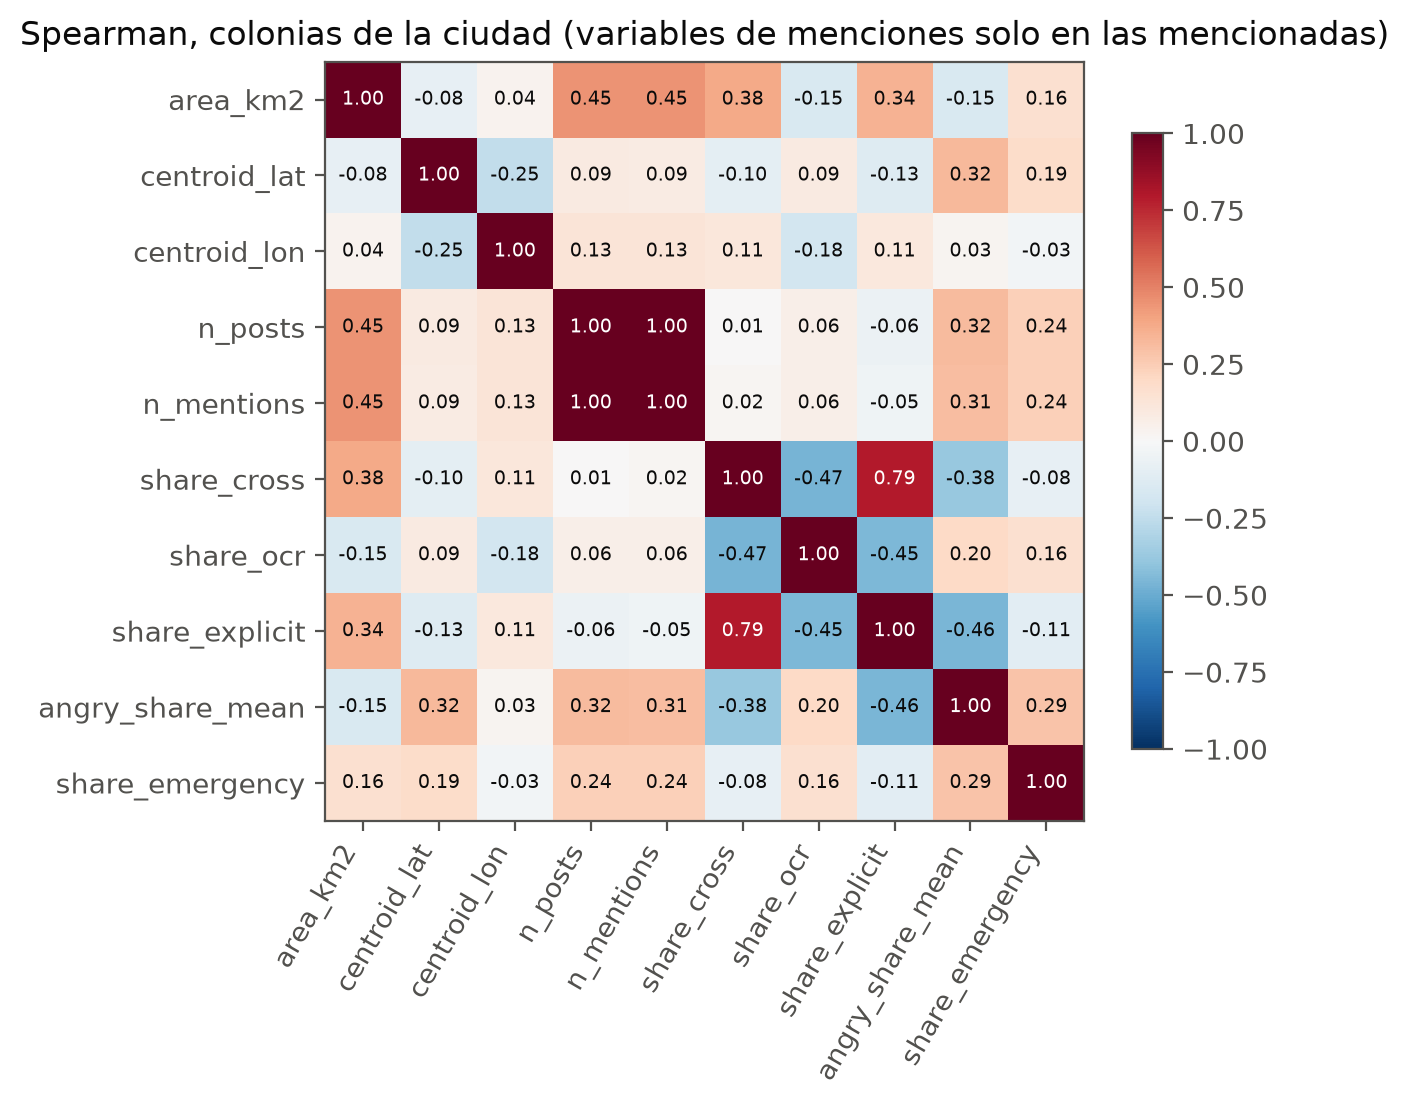

In [ ]:
profile_numeric = [
    "area_km2",
    "centroid_lat",
    "centroid_lon",
    "n_posts",
    "n_mentions",
    "share_cross",
    "share_ocr",
    "share_explicit",
    "angry_share_mean",
    "share_emergency",
]
_city = colonia_profile[colonia_profile["locality_code"] == "0001"]
plot_heatmap(
    _city[profile_numeric].corr("spearman"),
    "Spearman, colonias de la ciudad (variables de menciones solo en las mencionadas)",
)

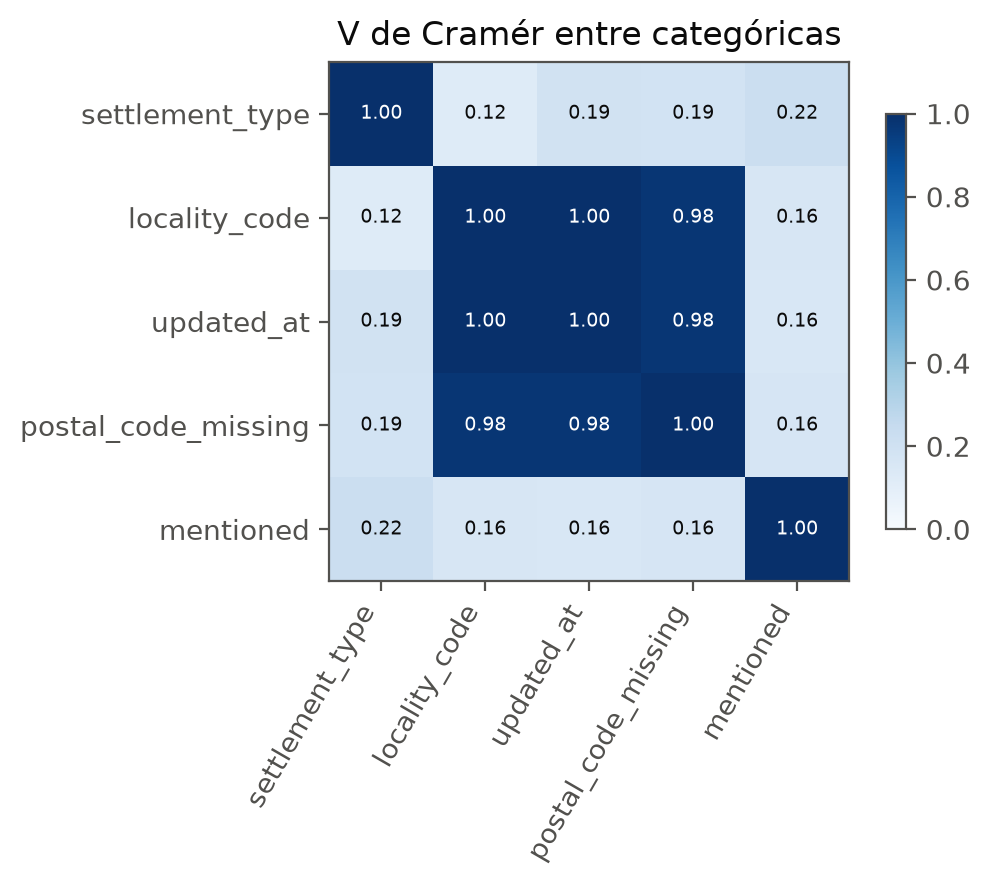

In [ ]:
_categorical = colonia_profile.assign(
    postal_code_missing=colonia_profile["postal_code"] == "00000",
    mentioned=colonia_profile["mentioned"],
).astype({"postal_code_missing": str, "mentioned": str})
plot_heatmap(
    cramers_v_matrix(
        _categorical,
        ["settlement_type", "locality_code", "updated_at", "postal_code_missing", "mentioned"],
    ),
    "V de Cramér entre categóricas",
    diverging=False,
)

In [ ]:
pd.Series(
    {
        "log(area_km2)": correlation_ratio(
            colonia_profile["settlement_type"], colonia_profile["log_area"]
        ),
        "log1p(n_posts)": correlation_ratio(
            colonia_profile["settlement_type"], np.log1p(colonia_profile["n_posts"])
        ),
        "angry_share_mean": correlation_ratio(
            colonia_profile["settlement_type"], colonia_profile["angry_share_mean"]
        ),
    },
    name="eta con settlement_type",
).round(3).to_frame()

,eta con settlement_type
log(area_km2),0.336
log1p(n_posts),0.372
angry_share_mean,0.155


- `locality_code`, `updated_at` y el código postal `00000` son prácticamente la misma
  variable (V de Cramér cercana a 1): todo lo rural se actualizó en 2022 y no tiene código
  postal. Basta con `locality_code`.
- `share_cross` y `share_explicit` están muy correlacionadas (0.79) porque los cruces
  cuentan como menciones explícitas; y ambas van en contra de `share_ocr` (-0.47 y
  -0.45): los volantes casi nunca traen cruces ni la palabra "colonia", traen listas de
  nombres.
- `angry_share_mean` correlaciona en negativo con `share_explicit` (-0.46) y en positivo
  con la latitud (0.32) y con `n_posts` (0.32): las colonias que aparecen sobre todo en
  listas, las del norte y las más mencionadas acumulan avisos con más enojo.
- `n_posts` y `n_mentions` son la misma variable (1.00): una colonia rara vez se menciona
  dos veces en un aviso.
- `settlement_type` explica parte del área (eta 0.34) y del número de publicaciones
  (eta 0.37), sobre todo por la diferencia entre colonias y fraccionamientos.

## 6. Reducción de dimensión para visualización

Variables (estandarizadas): logaritmo del área, latitud, longitud, `log1p(n_posts)`,
`mentioned` y las cinco proporciones de menciones (0 si la colonia no se menciona). Se
usan solo las 762 colonias de la ciudad, porque las rurales dominarían la latitud y la
longitud y la proyección solo separaría ciudad de campo. Con 762 filas, t-SNE usa
perplejidad 30.

In [ ]:
city_profile = colonia_profile[colonia_profile["locality_code"] == "0001"].reset_index(
    drop=True
)
_shares = ["share_cross", "share_ocr", "share_explicit", "angry_share_mean", "share_emergency"]
city_features = (
    city_profile[["log_area", "centroid_lat", "centroid_lon"]]
    .assign(
        log_posts=np.log1p(city_profile["n_posts"]),
        mentioned=city_profile["mentioned"].astype(int),
    )
    .join(city_profile[_shares].fillna(0))
)
city_matrix = StandardScaler().fit_transform(city_features)
city_matrix.shape

In [ ]:
_pca = PCA().fit(city_matrix)
print(
    "Varianza explicada acumulada:",
    _pca.explained_variance_ratio_.cumsum().round(2)[:5].tolist(),
)
pd.DataFrame(
    _pca.components_[:2].T, index=city_features.columns, columns=["PC1", "PC2"]
).round(2).sort_values("PC1")

Varianza explicada acumulada: [0.33, 0.54, 0.67, 0.76, 0.84]


,PC1,PC2
centroid_lon,0.01,0.11
centroid_lat,0.06,-0.17
share_cross,0.12,0.62
share_explicit,0.20,0.61
log_area,0.25,0.19
share_ocr,0.31,-0.32
share_emergency,0.33,-0.03
angry_share_mean,0.45,-0.22
log_posts,0.46,-0.11
mentioned,0.51,0.05


In [ ]:
city_embeddings = embed_2d(city_matrix)

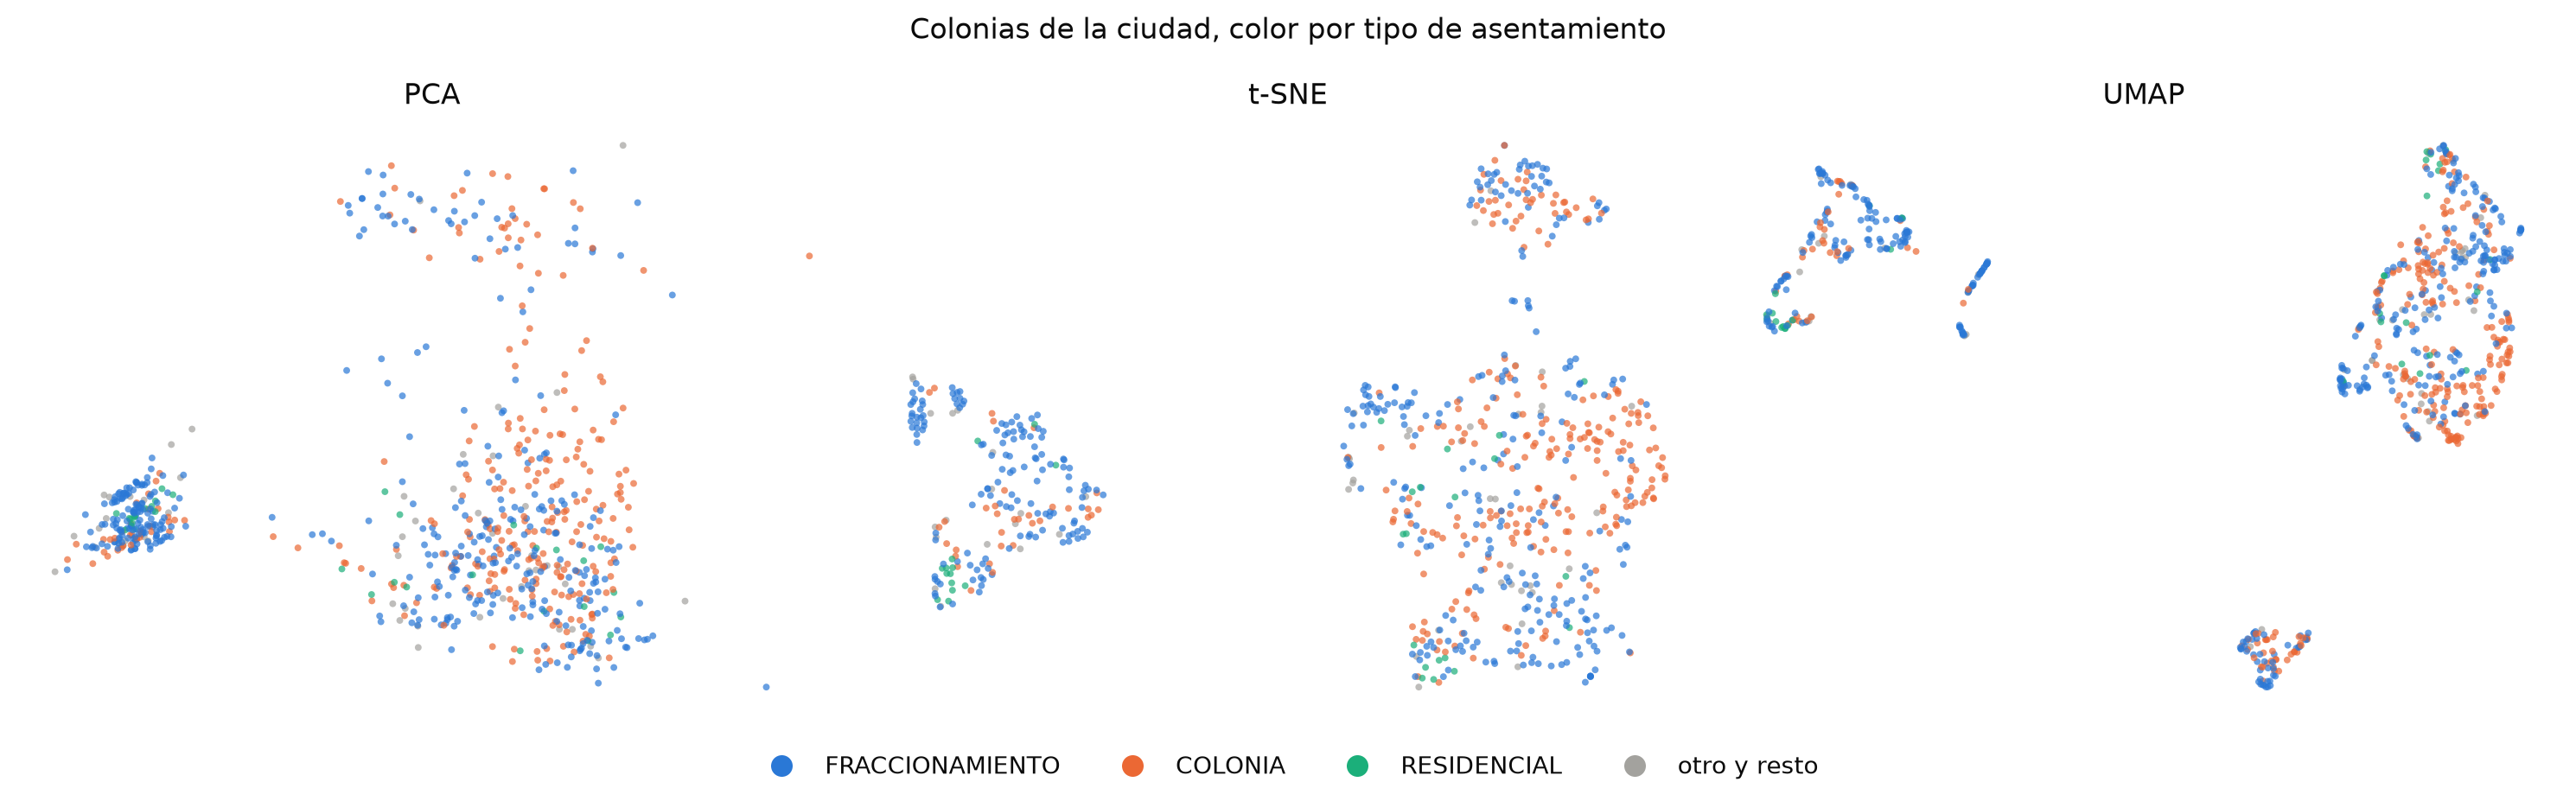

In [ ]:
plot_embeddings(
    city_embeddings,
    city_profile["settlement_type"],
    "Colonias de la ciudad, color por tipo de asentamiento",
    top=3,
)

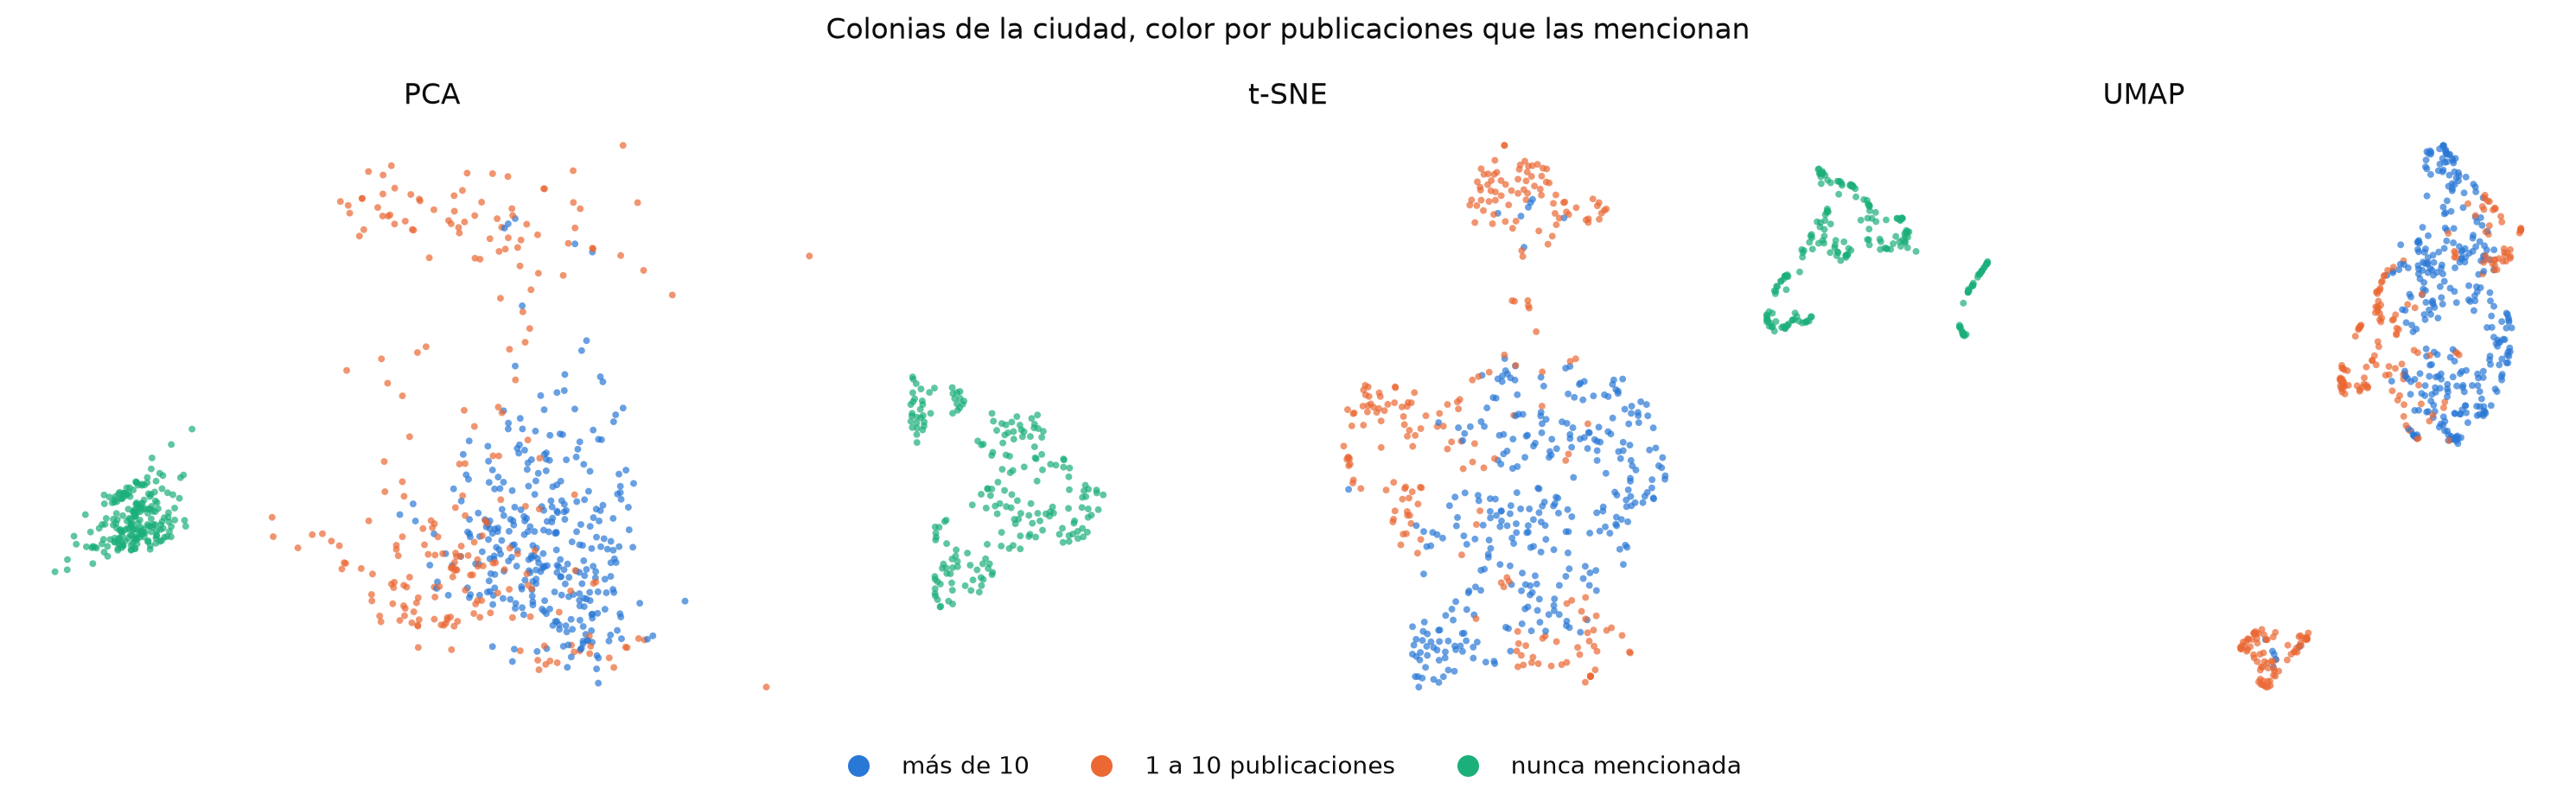

In [ ]:
_activity = pd.cut(
    city_profile["n_posts"],
    bins=[-np.inf, 0, 10, np.inf],
    labels=["nunca mencionada", "1 a 10 publicaciones", "más de 10"],
).astype(str)
plot_embeddings(
    city_embeddings,
    _activity,
    "Colonias de la ciudad, color por publicaciones que las mencionan",
)

In [ ]:
embedding_quality(city_matrix, city_embeddings).to_frame()

,trustworthiness
PCA,0.896
t-SNE,0.984
UMAP,0.976


- PCA: las dos primeras componentes explican 54% de la varianza. PC1 es la actividad en
  avisos (`mentioned`, `log_posts`, `angry_share_mean`); PC2 opone las menciones
  explícitas o por cruce (0.61 y 0.62) a las que salen del OCR (-0.32). El área y la
  ubicación casi no pesan en ninguna.
- Las tres proyecciones separan un grupo compacto: las 206 colonias nunca mencionadas,
  que tienen todas sus proporciones en 0. t-SNE y UMAP separan además, dentro de las
  mencionadas, las de 1 a 10 publicaciones de las de más de 10.
- Los tipos de asentamiento se mezclan en las tres: el tipo no define un perfil propio una
  vez que se conoce la actividad.
- Trustworthiness de 0.90 (PCA) a 0.98 (t-SNE): con 10 variables y 762 filas, PCA ya es
  fiel y más fácil de explicar.

## 7. Consulta con los usuarios

| # | Hallazgo | Pregunta |
|---|---|---|
| 1 | 221 colonias (28%) nunca aparecen en un aviso, sobre todo fraccionamientos y privadas | ¿Esas colonias se abastecen de otra red, o el organismo las nombra de otra forma (por sector, por calle)? ¿Cómo quieren verlas en el mapa? |
| 2 | "Centro", "Solidaridad" y "Sahuaro" se cuentan sobre todo por el nombre suelto, que también es un sector o un bulevar | ¿Cuando un aviso dice "Centro" o "Solidaridad" se refiere a la colonia o a una zona más amplia? |
| 3 | Hay menciones resueltas a colonias de Bahía de Kino y Miguel Alemán | ¿Agua de Hermosillo da servicio en esas localidades? Si no, se excluyen del emparejamiento. |
| 4 | 18 nombres se repiten en 38 asentamientos (colonia y su ampliación o privada) | ¿Les basta ver la colonia principal, o necesitan distinguir la ampliación? |
| 5 | Las colonias del norte y las que aparecen en listas largas acumulan avisos con más enojo | ¿Coincide con su experiencia? ¿Hay zonas que esperarían ver y no aparecen? |